# StaffPilot: dynamic agent staffing with a GenAI planning assistant

IE5374 Applied Generative AI, Module 7 Hackathon, Topic 3 (problem contributed by Google).

**Seven Team-5374** · *Trio Intelligence* · Copyright © 2026 Seven Team-5374

**Question.** How many support agents should each of 22 countries have in each month of the planning year, given uncertain sign ups, a 10 advertiser capacity per agent, a 60 day waiting pool, one month of ramp up and a firing cost of 40 percent of salary?

**Answer in one line.** January headcount is roughly three times what demand needs. Giving notice in January, hiring a few agents back before the fourth quarter and growing Vietnam raises expected net value by about 109 million dollars (30 percent) while serving every eligible advertiser with waits of about a day. A GenAI assistant puts the model in a manager's hands: it reads questions into typed requests, runs the planner as a tool, and only reports numbers that the planner produced.

Sections (brief requirement numbers as in the README): 1 setup and data (R16) · 2 rules and assumptions (R3 to R11) · 3 sign up data (R20) · 4 forecast (R24) · 5 simulator checks (R5 to R10) · 6 two countries first (R23) · 7 policies compared (R12, R13) · 8 the monthly plan (R1, R2) · 9 service versus value · 10 sensitivity and Monte Carlo (R14) · 11 assumptions that matter · 12 backtest on real sign ups · 13 other considerations (R15) · 14 the GenAI application (R17 to R22) · 15 multi LLM evaluation · 16 conclusions (R29).

> Every section was drafted with AI assistance and is marked as such; see docs/AI_USAGE.md for what was checked and how.

## 1. Setup and data

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from staffpilot import Planner, ScenarioParams, load_settings
from staffpilot.agent import StaffPilot, available_providers
from staffpilot.planner import RECOMMENDED_POLICY
from staffpilot.logs import configure_logging

configure_logging("WARNING", run_name="notebook")  # "INFO" or "DEBUG" shows what the planner and assistant do
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

settings = load_settings()
planner = Planner(settings)
data = planner.dataset
print(f"Source file: {Path(data.source).name}")
print(f"History years {data.history_years}, planning year {planner.year}, {len(planner.countries)} countries")
print(f"{len(data.signups):,} sign ups, {int(data.signups['eligible'].sum()):,} eligible ({data.signups['eligible'].mean():.1%})")
data.countries.head()

Source file: DADS5250_Hackathon_Google_Data.xlsx
History years [2024, 2025], planning year 2026, 22 countries
499,644 sign ups, 212,334 eligible (42.5%)


,salary,threshold,agents
country,,,
USA,"77,721.000","35,000.000",652
UK,"51,650.000","27,000.000",589
Germany,"51,328.000","26,000.000",602
India,"14,118.000","13,000.000",428
Brazil,"27,950.000","29,000.000",189


## 2. Rules and assumptions

The brief rules are settings, not constants in code, and every open point is a switch. The planning year comes from the data, so the IE5374 file (2023 and 2024, plan 2025) and the public copy used here (2024 and 2025, plan 2026) both work by changing one path in `config/staffpilot.toml`.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [2]:
rules = settings.rules
print(f"capacity {rules.capacity_per_agent} advertisers per agent, support {rules.support_days} days, max wait {rules.max_wait_days} days")
print(f"ramp up {rules.ramp_months} month, notice {rules.notice_months} month, firing cost {rules.fire_cost_share:.0%} of annual salary")
print(f"expected uplift {rules.expected_uplift:.3f}")
print("assumptions:", settings.assumptions.model_dump())

capacity 10 advertisers per agent, support 60 days, max wait 60 days
ramp up 1 month, notice 1 month, firing cost 40% of annual salary
expected uplift 0.135
assumptions: {'uplift_base': 'annual_budget', 'initial_pool': 'empty', 'queue_policy': 'fifo', 'pay_during_ramp': True}


## 3. Exploratory data analysis

Data quality first, then the patterns that drive the plan. The same report is written by `python -m staffpilot eda`.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [3]:
from staffpilot.eda import budget_figure, figures, profile

report = profile(data, settings.rules.capacity_per_agent)
for finding in report.findings:
    print("*", finding)
report.quality

* 42.5% of 499,644 sign ups clear their country threshold.
* January headcount is 6,474 agents against a peak need of about 2,333, 2.8 times what the busiest 60 days require.
* Demand peaks in Nov and is lowest in Jun; the peak month is 1.8 times the quietest.
* Day to day noise is high: the median daily coefficient of variation is 0.69, far above what steady random arrivals would give, so the waiting pool matters.
* Understaffed in January: Vietnam.
* Eligible sign ups changed by -1.8% (median country) between the two years.
* Weekdays differ by only 12% from each other, so weekly patterns can be ignored.


,check,value,note
0,Rows,499644,one row per sign up
1,Missing values,0,across all columns
2,Duplicate advertiser ids,0,
3,Impossible dates repaired,920,moved to the last day of the month
4,Budgets at or below zero,0,
5,Budgets exactly on the threshold,13,ineligible under the strict rule
6,Countries,22,


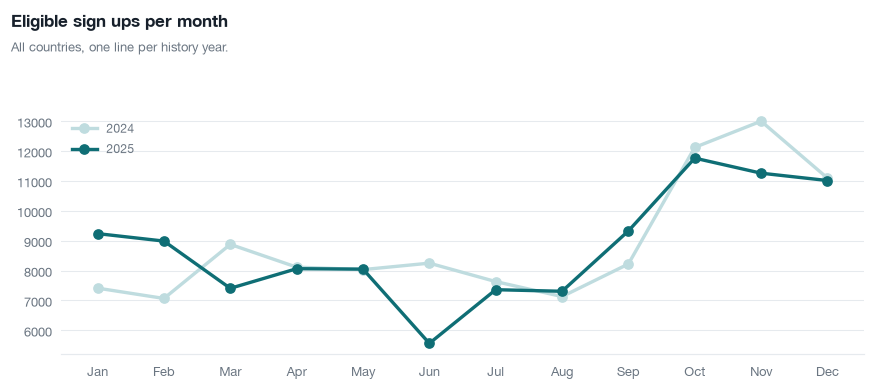

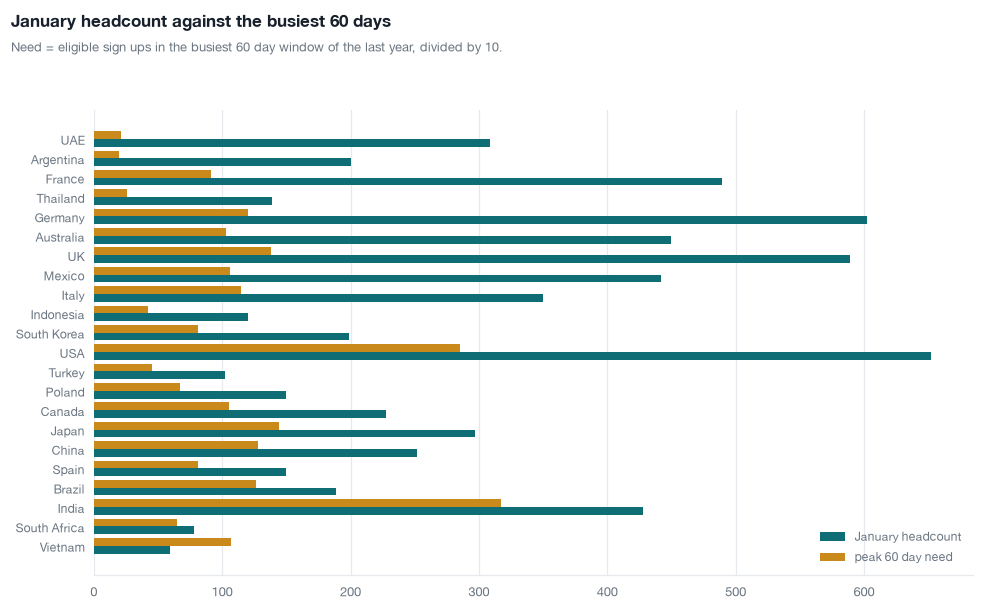

In [4]:
eda_figures = figures(report)
display(eda_figures["monthly_trend"], eda_figures["staff_vs_need"])

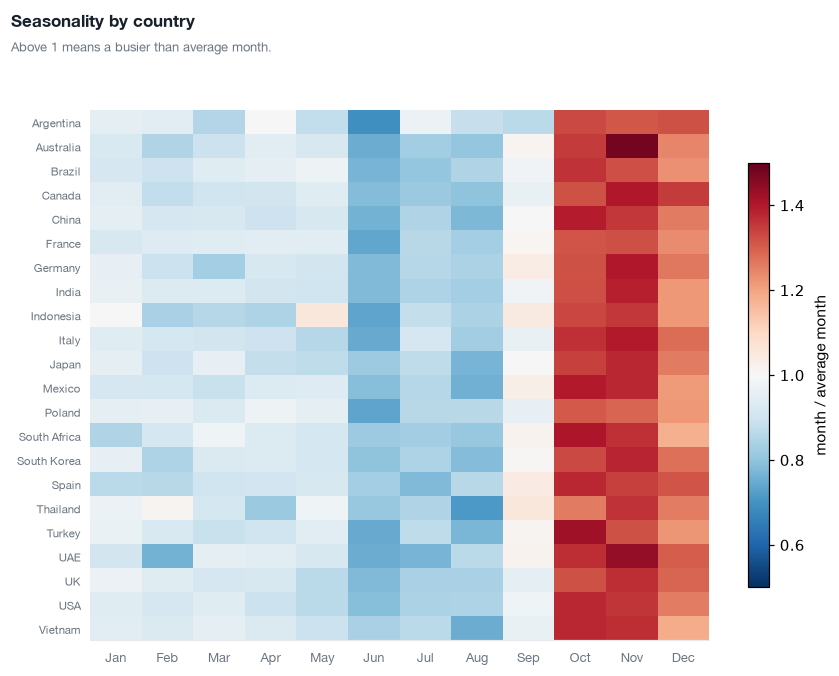

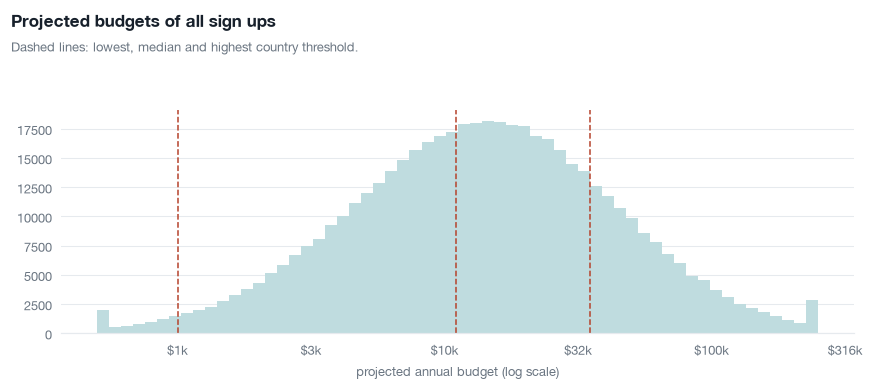

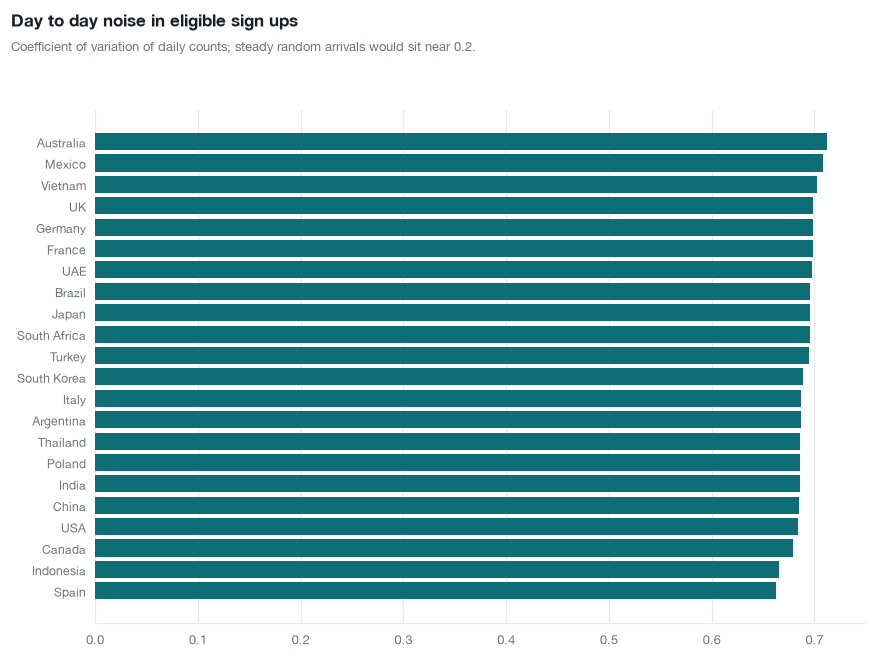

In [5]:
display(eda_figures["seasonality_heatmap"], budget_figure(data), eda_figures["daily_noise"])

In [6]:
report.countries[["country", "signups", "eligible_rate", "median_eligible_budget", "threshold", "agents", "peak_need", "staff_to_need", "yearly_change", "daily_cv"]].sort_values("staff_to_need", ascending=False)

,country,signups,eligible_rate,median_eligible_budget,threshold,agents,peak_need,staff_to_need,yearly_change,daily_cv
18,UAE,3014,0.658,"2,418.000","1,000.000",309,21.000,14.714,-0.038,0.698
0,Argentina,5869,0.307,"8,428.000","5,000.000",200,20.000,10.000,-0.021,0.686
5,France,26859,0.311,"37,326.000","22,000.000",489,91.000,5.374,-0.029,0.698
16,Thailand,6041,0.392,"7,133.500","4,000.000",139,26.000,5.346,0.040,0.686
6,Germany,33183,0.324,"43,967.000","26,000.000",602,120.000,5.017,0.002,0.699
1,Australia,23966,0.387,"28,349.000","16,000.000",450,103.000,4.369,-0.025,0.713
19,UK,36247,0.343,"46,501.000","27,000.000",589,138.000,4.268,-0.022,0.699
11,Mexico,18140,0.546,"16,625.000","8,000.000",442,106.000,4.170,-0.057,0.708
9,Italy,21053,0.487,"21,446.000","11,000.000",350,115.000,3.043,-0.003,0.687
8,Indonesia,12110,0.302,"16,674.500","10,000.000",120,42.000,2.857,-0.005,0.665


## 4. Forecast

Three seasonal methods are backtested: train on the first year, predict the second. With one training year they tie, so the seasonal mean of both years is used because it draws on the most data.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [7]:
bt = planner.forecast.backtest
print("chosen method:", planner.forecast.method)
bt.groupby("method")["mape"].describe()[["mean", "50%", "max"]]

chosen method: seasonal_mean


,mean,50%,max
method,,,
last_year,15.114,14.186,23.011
seasonal_mean,15.114,14.186,23.011
seasonal_trend,15.114,14.186,23.011


## 5. Simulator checks and the flow model

Every number reported later comes from a day by day simulator. A slot counts as free only if it exists for the whole 60 day support under the plan, so an agent under notice takes no new advertisers and the 10 advertiser limit holds every day. The first checks can be verified by hand.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [8]:
from staffpilot.forecast import DemandStream
from staffpilot.simulate import simulate

def stream(days, arrivals):
    return DemandStream([np.array(arrivals.get(d, []), float) for d in range(days)], [])

months = np.minimum(np.arange(130) // 30, 11)
no_agents = simulate(stream(130, {0: [1000.0] * 5}), np.zeros(12), months, rules, settings.assumptions)
one_agent = simulate(stream(130, {0: [1000.0] * 10, 1: [1000.0]}), np.ones(12), months, rules, settings.assumptions)
cut = np.array([4, 1] + [1] * 10)
arrivals = stream(130, {d: [1000.0] * 3 for d in range(40)})
aware = simulate(arrivals, cut, months, rules, settings.assumptions)
greedy = simulate(arrivals, cut, months, rules, settings.assumptions, dispatch="greedy")
print("0 agents, 5 sign ups: served", no_agents.totals(12)["served"], "dropped", no_agents.totals(12)["dropped"])
print("1 agent, 11 sign ups: longest wait", int(one_agent.waits.max()), "days (the slot frees after 60 days)")
print("headcount cut from 4 to 1: overflow", aware.monthly["max_overflow"].max(), "with the notice rule,", greedy.monthly["max_overflow"].max(), "if free slots are filled greedily")

0 agents, 5 sign ups: served 0.0 dropped 5.0
1 agent, 11 sign ups: longest wait 59 days (the slot frees after 60 days)
headcount cut from 4 to 1: overflow 0.0 with the notice rule, 30.0 if free slots are filled greedily


Our first simulator filled today's free slots greedily and showed plans breaking the 10 advertiser limit whenever headcount was cut. We first blamed the optimizer's monthly flows, but the real fix was the dispatch rule above. With that rule in place, the table compares a simple optimizer (advertiser flows by month, 60 days treated as two months) with the weekly one we use.

In [9]:
flows = planner.flow_resolution_check()
flows.assign(net_value=flows["net_value"] / 1e6).rename(columns={"net_value": "net_value ($M)"})

,flows,dispatch,net_value ($M),service_rate,avg_active,mean_wait_days,p90_wait_days,worst_overflow
0,month,notice_aware,481.117,0.991,"2,109.083",1.969,7.000,0.000
1,month,greedy,481.146,0.991,"2,109.083",1.963,7.000,75.000
2,week,notice_aware,479.684,0.991,"2,206.167",1.099,5.000,0.000
3,week,greedy,479.713,0.991,"2,206.167",1.098,5.000,75.000


Both models are feasible under the notice rule. The monthly model keeps fewer agents and earns about 1.4 million dollars more, but advertisers wait almost twice as long. We keep weekly flows because the brief asks for timely support, and say so rather than claim the weekly model is required.

## 6. Walking skeleton: two countries first

Germany (most overstaffed) and Vietnam (understaffed) before scaling to all 22.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [10]:
two = planner.run("optimized", ["Germany", "Vietnam"])
two.kpi_table()[["country", "start_agents", "end_agents", "avg_active", "hires", "notices", "service_rate", "mean_wait_days", "net_value"]]

,country,start_agents,end_agents,avg_active,hires,notices,service_rate,mean_wait_days,net_value
0,Germany,602.000,102.000,133.417,16.000,516.000,1.000,1.350,"24,042,953.650"
1,Vietnam,59.000,95.000,79.417,36.000,0.000,1.000,1.343,"10,001,336.290"


## 7. All countries: policies compared

Baselines: keep January headcount (hold), match last month's demand (reactive), one cut to the yearly peak plus 10 percent (peak cover). Optimized plans come from a mixed integer program per country (monthly decisions, weekly advertiser flows, three months of lookahead), then are scored by the simulator. The recommended plan adds a 98 percent service floor.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [11]:
comparison = planner.compare_policies()
money = ["net_value", "net_value_vs_hold", "uplift_value", "salary_cost", "fire_cost", "total_cost"]
view = comparison[["policy", *money, "service_rate", "avg_active", "mean_wait_days"]].copy()
view[money] = view[money] / 1e6
view.rename(columns={c: f"{c} ($M)" for c in money})

,policy,net_value ($M),net_value_vs_hold ($M),uplift_value ($M),salary_cost ($M),fire_cost ($M),total_cost ($M),service_rate,avg_active,mean_wait_days
0,hold,370.379,0.000,656.562,286.183,0.000,286.183,0.993,"6,474.000",1.046
1,reactive,468.342,97.963,658.116,91.730,98.045,189.775,1.000,"2,133.417",1.734
2,peak_cover,464.141,93.762,658.116,121.702,72.273,193.975,1.000,"2,977.833",0.000
3,optimized,479.684,109.304,657.643,90.819,87.140,177.959,0.991,"2,206.167",1.099
4,service_98,479.653,109.274,658.116,91.714,86.749,178.464,1.000,"2,219.917",1.129


Reading the table: uplift is almost the same under every policy, because nearly every eligible advertiser is served either way. The whole gain is lower cost. A sensible heuristic (reactive) gets most of it; the optimizer adds about 11 million dollars more and, unlike the heuristics, handles hiring caps, service floors and scenarios in one model.

## 8. The recommended monthly plan

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [12]:
bundle = planner.run(RECOMMENDED_POLICY)
plan = bundle.plan_table()
plan.to_csv("../outputs/plan.csv", index=False)
active = plan.pivot(index="country", columns="month", values="active_agents")
active.columns = [c[-2:] for c in active.columns]
active

,01,02,03,04,05,06,07,08,09,10,11,12
country,,,,,,,,,,,,
Argentina,200,15,15,15,15,15,15,15,15,17,17,17
Australia,450,74,74,74,74,74,74,74,74,74,89,89
Brazil,189,97,97,97,97,97,97,97,97,116,116,116
Canada,228,76,76,76,76,76,76,76,76,86,91,91
China,252,102,102,102,102,102,102,102,102,118,126,126
France,489,70,70,70,70,70,70,70,70,78,79,79
Germany,602,86,86,86,86,86,86,86,91,102,102,102
India,428,248,248,248,248,248,248,248,248,286,300,300
Indonesia,120,30,30,30,30,30,30,30,33,33,37,37


In [13]:
changes = plan[(plan["hires_decided"] > 0) | (plan["notices_given"] > 0)][["country", "month", "hires_decided", "notices_given", "agents_in_notice", "active_agents"]]
print(f"{len(changes)} country months with a hiring or notice decision")
changes.head(25)

57 country months with a hiring or notice decision


,country,month,hires_decided,notices_given,agents_in_notice,active_agents
0,USA,2026-01,0,439,439,652
8,USA,2026-09,37,0,0,213
9,USA,2026-10,2,0,0,250
12,UK,2026-01,0,487,487,589
20,UK,2026-09,14,0,0,102
21,UK,2026-10,4,0,0,116
24,Germany,2026-01,0,516,516,602
31,Germany,2026-08,5,0,0,86
32,Germany,2026-09,11,0,0,91
36,India,2026-01,0,180,180,428


In [14]:
kpis = bundle.kpi_table()
kpis[["country", "start_agents", "avg_active", "service_rate", "mean_wait_days", "p90_wait_days", "utilization", "avg_idle_agents", "roi", "net_value"]].sort_values("net_value", ascending=False)

,country,start_agents,avg_active,service_rate,mean_wait_days,p90_wait_days,utilization,avg_idle_agents,roi,net_value
20,USA,652.000,259.167,1.000,1.103,6.000,0.725,70.843,4.454,"117,576,997.085"
7,India,428.000,274.833,1.000,0.427,2.000,0.769,63.361,18.211,"85,328,092.895"
4,China,252.000,119.833,1.000,0.194,1.000,0.710,34.656,13.851,"52,026,248.313"
2,Brazil,189.000,109.417,1.000,0.451,2.000,0.765,25.586,11.873,"44,915,825.690"
19,UK,589.000,146.750,1.000,1.088,7.000,0.608,57.126,2.941,"34,384,533.765"
10,Japan,297.000,125.750,1.000,1.857,9.000,0.759,30.104,3.876,"29,077,085.745"
6,Germany,602.000,133.417,1.000,1.350,8.000,0.574,56.363,2.373,"24,042,953.650"
3,Canada,228.000,92.000,1.000,1.230,7.000,0.730,24.679,3.155,"20,274,458.970"
1,Australia,450.000,107.833,1.000,2.276,11.000,0.605,42.229,2.152,"13,000,746.538"
9,Italy,350.000,109.083,1.000,1.210,7.000,0.673,35.400,2.185,"11,095,629.635"


### Alerts

Checks a manager should see before acting on the plan. Each rule is a plain threshold, so the reason is visible.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [15]:
from staffpilot.alerts import plan_alerts

for alert in plan_alerts(planner):
    print(f"[{alert.level}] {alert.message}")

15:44:52 WARNING staffpilot.alerts: critical alert (data): This file plans 2026, but the brief asks for 2025. Load the official course file before using these numbers.


15:44:52 WARNING staffpilot.alerts: warning alert (waiting): One in ten advertisers waits more than two weeks in UAE.


15:44:52 WARNING staffpilot.alerts: warning alert (hiring): Vietnam must grow the team; hires decided in January only start in February, so approve them first.


15:44:52 WARNING staffpilot.alerts: warning alert (people): 18 countries let more than half of their January team go. Check local notice rules and plan the communication before notices are sent.


15:44:52 WARNING staffpilot.alerts: warning alert (value): In UAE support costs more than the uplift it brings at current salaries; keeping service there is a business decision.


[critical] This file plans 2026, but the brief asks for 2025. Load the official course file before using these numbers.
[warning] One in ten advertisers waits more than two weeks in UAE.
[warning] Vietnam must grow the team; hires decided in January only start in February, so approve them first.
[warning] 18 countries let more than half of their January team go. Check local notice rules and plan the communication before notices are sent.
[warning] In UAE support costs more than the uplift it brings at current salaries; keeping service there is a business decision.
[info] 920 sign ups had impossible dates (such as 29 February in a normal year) and were moved to the end of their month.
[info] The plan assumes uplift applies to the projected annual budget. If it only counts during the 60 days of support, every policy loses money; confirm this with Google before giving notice.


## 9. Service versus value

The same model with a floor on the share of eligible advertisers served.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [16]:
frontier = []
for target in (0.0, 0.90, 0.95, 0.98, 1.0):
    variant = Planner(settings.with_updates(planning={"service_target": target}), data)
    t = variant.run("optimized").totals()
    frontier.append({"service_floor": target, "service_rate": t["service_rate"], "net_value_M": t["net_value"] / 1e6, "avg_active": t["avg_active"]})
pd.DataFrame(frontier)

,service_floor,service_rate,net_value_M,avg_active
0,0.000,0.991,479.684,"2,206.167"
1,0.900,1.000,479.686,"2,219.000"
2,0.950,1.000,479.687,"2,219.000"
3,0.980,1.000,479.653,"2,219.917"
4,1.000,1.000,479.653,"2,219.917"


## 10. Sensitivity to sign up volume and Monte Carlo

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [17]:
sens = planner.sensitivity()
table = sens.pivot(index="demand_scale", columns="plan", values=["net_value", "service_rate", "mean_wait_days", "avg_active"])
table["net_value"] = table["net_value"] / 1e6
table

net_value           service_rate           mean_wait_days             avg_active          
plan         current plan replanned current plan replanned   current plan replanned current plan replanned
demand_scale                                                                                              
0.700             281.124   293.103        0.991     0.991          0.000     1.090    2,206.167 1,708.417
0.800             347.489   355.538        0.991     0.991          0.000     1.115    2,206.167 1,872.083
0.900             413.042   417.046        0.991     0.991          0.209     1.099    2,206.167 2,039.750
1.000             479.684   479.684        0.991     0.991          1.099     1.099    2,206.167 2,206.167
1.100             545.148   541.129        0.991     0.991          3.429     1.100    2,206.167 2,373.333
1.200             609.789   602.119        0.990     0.991         11.955     1.101    2,206.167 2,538.917
1.300             644.790   663.047        0.952     0.991         22.159     1.113    2,206.167 2,702.917

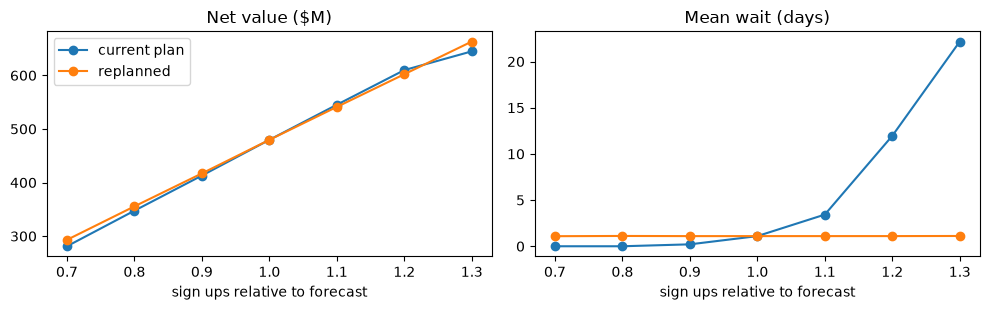

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for label, frame in sens.groupby("plan"):
    ax[0].plot(frame["demand_scale"], frame["net_value"] / 1e6, marker="o", label=label)
    ax[1].plot(frame["demand_scale"], frame["mean_wait_days"], marker="o", label=label)
ax[0].set(title="Net value ($M)", xlabel="sign ups relative to forecast")
ax[1].set(title="Mean wait (days)", xlabel="sign ups relative to forecast")
ax[0].legend(); plt.tight_layout(); plt.show()

When sign ups fall, replanning earns more because it lets surplus agents go. When they rise by 10 to 20 percent, the existing plan earns slightly more on paper because advertisers simply wait longer (up to about two weeks on average), which the brief counts as worse support; replanning keeps waits near one day. At 30 percent more sign ups the existing plan starts losing advertisers and replanning is clearly better.

In [19]:
mc = planner.monte_carlo(runs=20)
print("Monte Carlo over resampled daily sign ups and sampled uplift, 20 runs")
mc[["net_value", "service_rate", "dropped"]].describe(percentiles=[0.1, 0.5, 0.9]).loc[["mean", "10%", "50%", "90%"]]

Monte Carlo over resampled daily sign ups and sampled uplift, 20 runs


,net_value,service_rate,dropped
mean,"479,829,175.228",0.991,991.300
10%,"477,369,948.788",0.991,990.000
50%,"480,228,791.558",0.991,991.000
90%,"481,979,573.963",0.991,993.000


## 11. Which assumptions matter

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [20]:
variants = {
    "default": {},
    "A1 uplift on the 60 day window only": {"assumptions": {"uplift_base": "support_window"}},
    "A3 pool carries over on 1 January": {"assumptions": {"initial_pool": "carryover"}},
    "A8 highest budget served first": {"assumptions": {"queue_policy": "budget_priority"}},
    "A9 no preference for early service": {"planning": {"wait_penalty_per_week": 0.0}},
}
rows = []
for name, change in variants.items():
    variant = Planner(settings.with_updates(**change), data)
    compared = variant.compare_policies(policies=("hold", "optimized")).set_index("policy")
    t = variant.run("optimized").totals()
    rows.append({"assumption": name, "optimized_M": t["net_value"] / 1e6, "hold_M": compared.loc["hold", "net_value"] / 1e6,
                 "avg_active": t["avg_active"], "notices": t["notices"], "mean_wait_days": t["mean_wait_days"], "service_rate": t["service_rate"]})
pd.DataFrame(rows)

,assumption,optimized_M,hold_M,avg_active,notices,mean_wait_days,service_rate
0,default,479.684,370.379,"2,206.167","4,756.000",1.099,0.991
1,A1 uplift on the 60 day window only,-66.977,-178.255,"1,987.500","4,962.000",2.537,0.923
2,A3 pool carries over on 1 January,606.258,502.608,"2,576.000","4,434.000",8.090,0.991
3,A8 highest budget served first,478.652,370.933,"2,206.167","4,756.000",0.712,0.987
4,A9 no preference for early service,482.786,370.379,"2,103.333","4,810.000",3.030,0.991


A1 matters most. If uplift only counts during the 60 days of support, every policy loses money, yet the optimized plan still beats holding January headcount by more than 100 million dollars and gives even more notices. The question it raises is whether support pays for itself at all, which only Google can answer. A9 shows the price of timely support: dropping the preference for early service adds about 3 million dollars but nearly triples the average wait.

## 12. Backtest on real sign ups

Plan the last history year using only the year before it, then simulate on what actually happened. Hindsight is the same optimizer given the real daily sign ups.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [21]:
from staffpilot.backtest import run_backtest, summarize_backtest
summarize_backtest(run_backtest(settings, data))

,plan,net_value,avg_active,worst_overflow,service_rate,share_of_hindsight
0,hindsight,"474,190,835.113","2,217.500",0.000,0.989,1.000
1,optimized from forecast,"470,928,339.738","2,262.917",0.000,0.983,0.993
2,hold,"365,925,033.620","6,474.000",0.000,0.988,0.772


## 13. Other considerations

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [22]:
rows = []
for country in ("UK", "Germany", "France", "USA", "Mexico", "UAE"):
    r = planner.scenario(ScenarioParams(countries=[country], threshold_multiplier=0.8)).totals()
    rows.append({"country": country, "net_value_change_M": r["net_value_change"] / 1e6, "agents_change": r["avg_active_change"], "extra_served": r["served_change"]})
print("Lowering the eligibility threshold by 20 percent instead of letting idle capacity go:")
pd.DataFrame(rows)

Lowering the eligibility threshold by 20 percent instead of letting idle capacity go:


,country,net_value_change_M,agents_change,extra_served
0,UK,3.420,22.000,"1,533.000"
1,Germany,3.368,21.833,"1,392.000"
2,France,2.515,15.583,"1,082.000"
3,USA,9.015,41.167,"2,650.000"
4,Mexico,0.890,11.917,789.000
5,UAE,0.000,0.000,0.000


In [23]:
value_plan = planner.run("optimized").kpi_table().set_index("country")
recommended = kpis.set_index("country")
uae_cost = (value_plan.loc["UAE", "net_value"] - recommended.loc["UAE", "net_value"]) / 1e6
print(f"UAE: the pure value plan gives notice to all {int(value_plan.loc['UAE', 'notices'])} agents and serves {value_plan.loc['UAE', 'service_rate']:.0%};")
print(f"one agent's yearly uplift there is below its salary. The recommended plan keeps about {recommended.loc['UAE', 'avg_active']:.0f} agents on average,")
print(f"serves {recommended.loc['UAE', 'service_rate']:.0%} and costs ${uae_cost:,.2f}M of net value in total.")
print(f"Vietnam: starts with {int(recommended.loc['Vietnam', 'start_agents'])} agents and hires {int(recommended.loc['Vietnam', 'hires'])}; ROI {recommended.loc['Vietnam', 'roi']:.1f}.")

UAE: the pure value plan gives notice to all 309 agents and serves 0%;
one agent's yearly uplift there is below its salary. The recommended plan keeps about 40 agents on average,
serves 100% and costs $0.03M of net value in total.
Vietnam: starts with 59 agents and hires 36; ROI 7.8.


Further points for the report: cutting about two thirds of the workforce has morale, legal notice and employer brand costs the model does not price; notice rules in several countries are longer than one month; ramp up productivity is likely below full capacity; and serving high budgets first treats small advertisers worse.

## 14. The GenAI application

StaffPilot uses all six course techniques: API calls (OpenAI, Anthropic, Google through LangChain), prompt engineering (router, answer, memo and judge prompts), structured output (Pydantic `RoutedQuery`, `ScenarioParams`, `MemoDraft`), LangChain (`init_chat_model`, six tools, `create_agent` with memory), RAG (BM25 over the rules, assumptions and metric definitions, with citations) and agents.

Two agent designs are offered. The structured assistant routes each question to one intent and runs a fixed tool for it, which keeps answers predictable and easy to evaluate. The `create_agent` chat lets the model choose and chain tools itself, with memory per conversation. Every answer is written with `{{fact}}` placeholders that are filled from tool output; any number left in the text that no tool produced, or that belongs to another country, is rejected. Without API keys the offline backend (keyword router plus templates) runs the same pipeline.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

LLM providers with keys: none, using the offline backend
Q: How many agents does Germany need in March and why?
(plan_lookup, get_plan, number check passed)

Germany should start the year with 602 agents and finish it with 102, with about 133 at work in an average month. That keeps 100.0% of eligible advertisers served, with an average wait of 1.3 days, and earns $24.0M of net value.

Most of the change is a cut: 516 notices in total, the first in January. Notices take effect a month later, so nobody is dropped mid support.

The plan also hires 16 agents, starting in August, so they are trained before the busy months.

In March, 86 agents are working, with no hiring or notice decisions that month. 



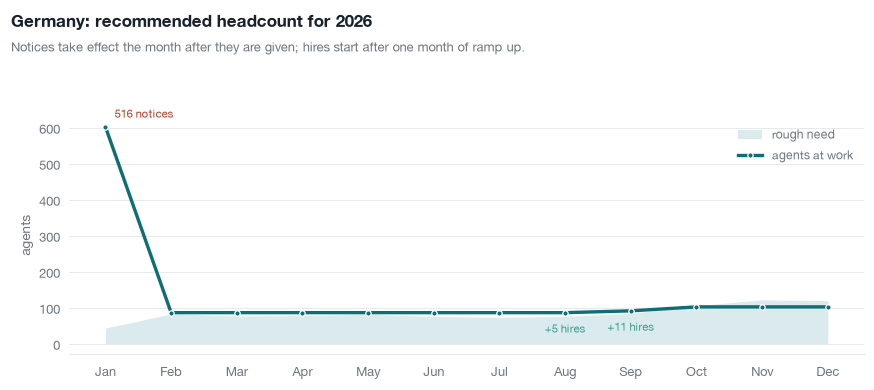

Q: What if sign ups in Brazil drop 30% in Q3?
(what_if, run_scenario, number check passed)

If sign ups fall 30% from July to September in Brazil, and we rebuild the plan, net value goes from $44.9M to $41.7M, a change of -$3.2M.

Headcount moves from about 109 to 108 agents in an average month, and service stays at 100.0%. 



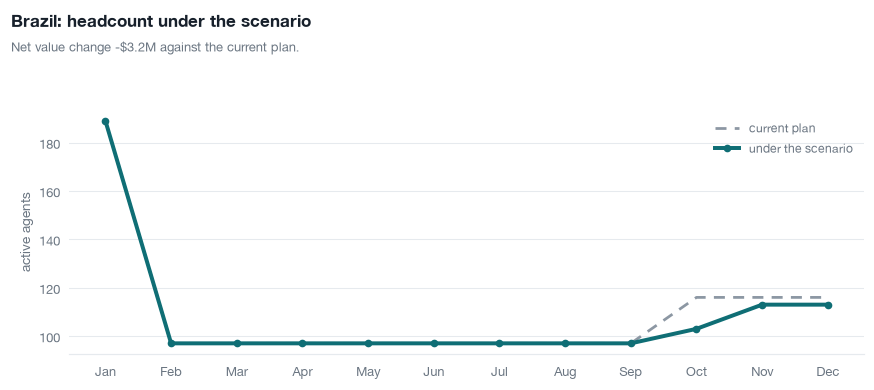

Q: Compare the optimized plan with keeping January headcount.
(compare, compare_policies, number check passed)

Keeping January headcount all year would earn $370.4M. The optimized plan earns $479.7M, which is $109.3M more, almost entirely because surplus agents are let go early rather than paid to wait for work.

It still serves 99.1% of eligible advertisers with about 2,206 agents at work in an average month. A simple rule that follows last month's demand gets most of the way there ($468.3M). 



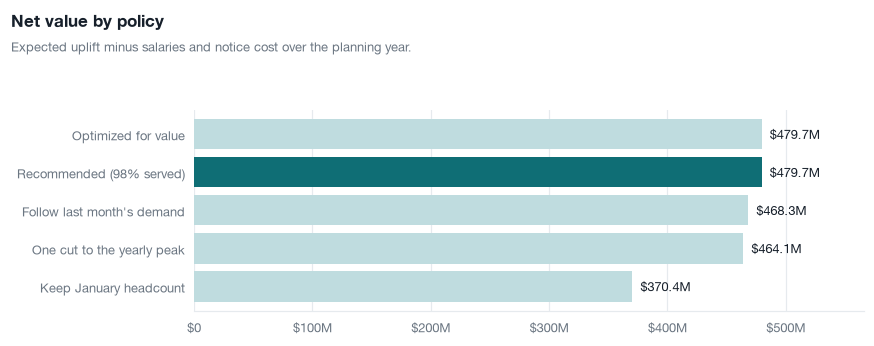

Q: What if we lower the eligibility threshold in the UK by 20 percent?
(what_if, run_scenario, number check passed)

If the eligibility threshold is lowered by 20% in UK, and we rebuild the plan, net value goes from $34.4M to $37.8M, a change of $3.4M.

Headcount moves from about 147 to 169 agents in an average month, and service stays at 100.0%. 



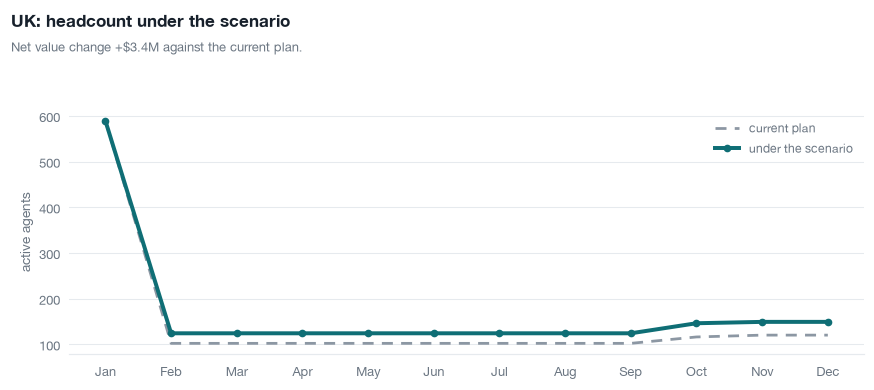

Q: Which countries have the most volatile demand?
(insight, signup_insights, number check passed)

UAE has the most volatile monthly demand; day to day noise is high everywhere. 



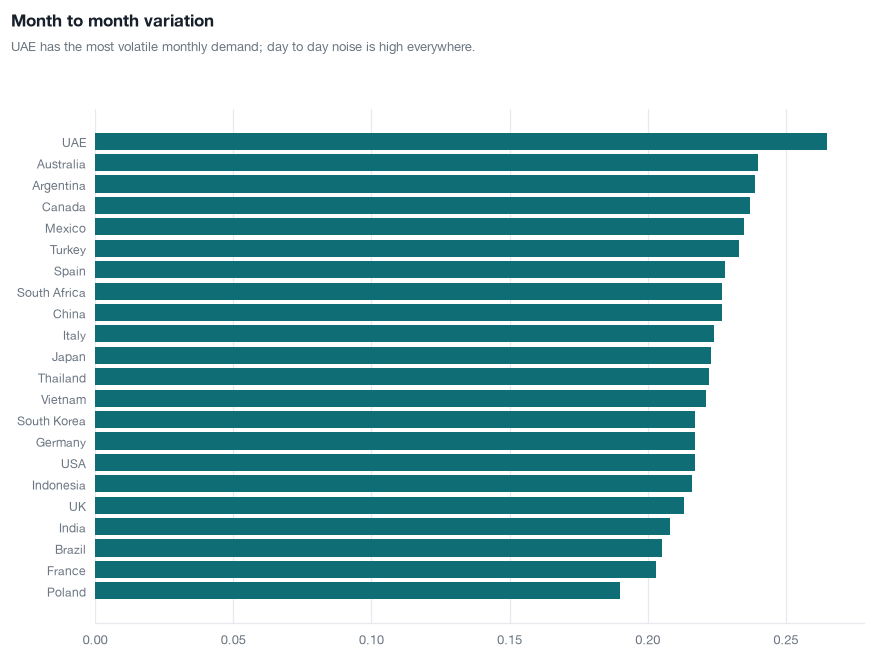

Q: How long can an advertiser wait in the pool?
(rules, search_rules, number check passed)

Here is what the case rules say.

[rules.md / Waiting pool] Eligible advertisers enter a waiting pool. If an agent has a free slot, the advertiser is assigned at once. If no slot is free, the advertiser waits in the pool for up to 60 days. An advertiser still unassigned after 60 days is removed from the pool and never receives support.

[kpis.md / Wait time] Days between sign up and assignment for advertisers who were assigned. Reported as the mean and the 90th percentile. 

Q: What if sign ups in Atlantis rise 20%?
(what_if, no tool, number check passed)

I do not have data for Atlantis. The countries in the data are USA, UK, Germany, India, Brazil, Japan, Australia, Canada, France, Mexico, China, Italy, Spain, Poland, South Korea, South Africa, Vietnam, Argentina, Turkey, Indonesia, Thailand, UAE. 



In [24]:
providers = available_providers()
print("LLM providers with keys:", providers or "none, using the offline backend")
pilot = StaffPilot.for_backend(planner, providers[0] if providers else "offline", Path("../eval/cache"))
questions = [
    "How many agents does Germany need in March and why?",
    "What if sign ups in Brazil drop 30% in Q3?",
    "Compare the optimized plan with keeping January headcount.",
    "What if we lower the eligibility threshold in the UK by 20 percent?",
    "Which countries have the most volatile demand?",
    "How long can an advertiser wait in the pool?",
    "What if sign ups in Atlantis rise 20%?",
]
for q in questions:
    a = pilot.ask(q)
    print(f"Q: {q}\n({a.route.intent.value}, {', '.join(a.tools) or 'no tool'}, number check {'passed' if a.verified else 'failed'})\n")
    print(a.text, "\n")
    if a.chart is not None:
        display(a.chart)

In [25]:
print(pilot.route("What if sign ups in Brazil drop 30% in Q3?")[0].model_dump_json(indent=2, exclude_none=True))

{
  "intent": "what_if",
  "countries": [
    "Brazil"
  ],
  "months": [
    7,
    8,
    9
  ],
  "scenario": {
    "countries": [
      "Brazil"
    ],
    "months": [
      7,
      8,
      9
    ],
    "demand_multiplier": 0.7,
    "threshold_multiplier": 1.0,
    "salary_multiplier": 1.0,
    "replan": true
  }
}


In [26]:
# Follow up questions: a Conversation keeps the last four turns, so short follow ups
# inherit the country, months and scenario they leave out.
from staffpilot.agent.memory import Conversation, describe
talk = Conversation()
for q in ["What if sign ups in Brazil drop 30% in Q3?", "And Mexico?", "What about 50 percent instead?"]:
    a = pilot.ask(q, talk)
    kept = f", kept the {describe(a.carried)}" if a.carried else ""
    print(f"Q: {q}\n({a.route.scenario.plain() if a.route.scenario else a.route.intent.value}{kept})\n{a.text}\n")

Q: What if sign ups in Brazil drop 30% in Q3?
(If sign ups fall 30% from July to September in Brazil, and we rebuild the plan)
If sign ups fall 30% from July to September in Brazil, and we rebuild the plan, net value goes from $44.9M to $41.7M, a change of -$3.2M.

Headcount moves from about 109 to 108 agents in an average month, and service stays at 100.0%.



Q: And Mexico?
(If sign ups fall 30% from July to September in Mexico, and we rebuild the plan, kept the kind of question, months and scenario)
If sign ups fall 30% from July to September in Mexico, and we rebuild the plan, net value goes from $10.5M to $9.5M, a change of -$1.0M.

Headcount moves from about 116 to 113 agents in an average month, and service stays at 100.0%.



Q: What about 50 percent instead?
(If sign ups fall 50% from July to September in Mexico, and we rebuild the plan, kept the kind of question, countries, months and scenario)
If sign ups fall 50% from July to September in Mexico, and we rebuild the plan, net value goes from $10.5M to $8.8M, a change of -$1.7M.

Headcount moves from about 116 to 113 agents in an average month, and service stays at 100.0%.



### Staffing memo: Vietnam, 2026

Vietnam: move from 59 to 95 agents, averaging 79.4 active agents.

**Headcount changes**
* Hire 36 agents in total; the first hiring decision is in month 1, and new agents start one month later.

**Cost and value**
* Salary cost $1.5M and firing cost $0.
* Expected uplift value $11.5M, net value $10.0M.
* Service rate 100.0% with an average wait of 1.3 days.

**Why**
* Headcount follows forecast eligible sign ups, with each agent holding at most 10 advertisers for 60 days.
* Notices cost 40.0% of annual salary, so cuts happen early when the saving over the rest of the year is larger than that cost.

**Risks to watch**
* Sign ups vary a lot from day to day; the waiting pool absorbs short peaks but not a sustained rise.
* The value of support assumes uplift applies to the projected annual budget.

number check: passed


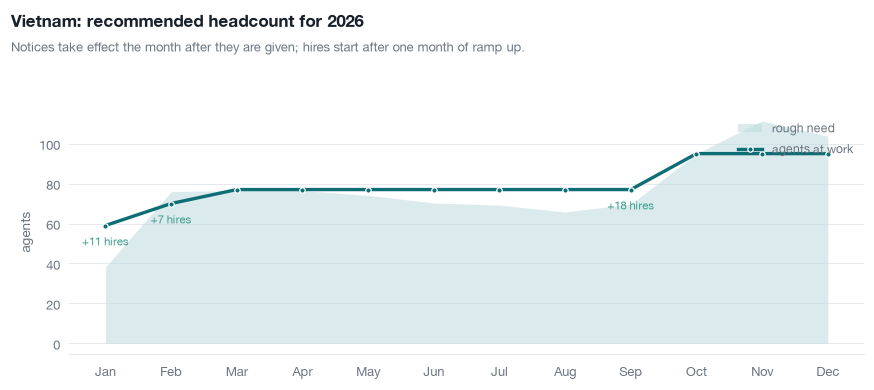

In [27]:
memo = pilot.memo("Vietnam")
print(memo.text)
print("number check:", "passed" if memo.verified else memo.unsupported)
display(memo.chart)

In [28]:
from staffpilot.agent.tools import PlannerTools
print("LangChain tools:", [t.name for t in PlannerTools(planner).as_langchain_tools()])
if providers:
    from staffpilot.agent.chat_agent import build_chat_agent, chat
    from staffpilot.agent.catalog import pick_model
    agent = build_chat_agent(PlannerTools(planner), pick_model(settings, providers[0], "strong"), settings)
    reply = chat(agent, "Which three countries cut the most agents, and how many?", thread_id="demo")
    print(reply.text, "\ntools:", reply.tools_called, "unsupported:", reply.unsupported)
    print(chat(agent, "And the first of those, what is its net value?", thread_id="demo").text)
else:
    print("The free form create_agent chat needs an API key; see README.")

LangChain tools: ['get_plan', 'compare_policies', 'run_scenario', 'sensitivity', 'signup_insights', 'search_rules']
The free form create_agent chat needs an API key; see README.


## 15. Multi LLM evaluation

Forty labelled questions (`eval/testset.jsonl`) and a 32 question holdout written in different words (`eval/holdout.jsonl`). Metrics: intent, country and scenario field accuracy; grounded rate (passes the number check without the template fallback, always true for the offline templates); a 1 to 5 judge score averaged over judge models of other providers, with a written rubric; tool choice accuracy of the `create_agent` chat; tokens, cost and latency. Strong and fast tiers are compared separately so models face their peers. The offline keywords were written while looking at the main set, so the holdout is the fair comparison. The table below is read from `eval/results/`, written by `python -m staffpilot eval`; building the notebook never reruns the evaluation, so it never calls a model. Run that command with API keys to add the language model rows (replies are cached in `eval/cache`), then rebuild the notebook.

*AI assisted: drafted with an AI coding assistant, then run, checked and edited by the team.*

In [29]:
results = Path("../eval/results")
if not (results / "summary.csv").exists():
    # First run only, and free: the offline backend needs no model.
    from staffpilot.evaluation import run_evaluation
    splits = {name: Path(f"../eval/{name}.jsonl") for name in ("testset", "holdout", "followups")}
    run_evaluation(planner, ["offline"], {"main": splits["testset"], "holdout": splits["holdout"],
                                          "followups": splits["followups"]}, results, None)
summary = pd.read_csv(results / "summary.csv")
summary

,split,backend,cases,errors,intent_accuracy,country_accuracy,scenario_accuracy,grounded_rate,judge_score,agent_tool_accuracy,tokens_per_question,cost_per_question_usd,mean_seconds
0,followups,local:google/gemma-4-e4b,10.000,0.000,1.000,1.000,0.875,0.700,4.400,NaN,"3,213.400",NaN,61.855
1,followups,local:meta-llama-3.1-8b-instruct,10.000,0.000,0.900,0.900,0.667,1.000,4.100,NaN,"1,124.300",NaN,11.560
2,followups,offline,10.000,0.000,0.900,1.000,0.750,1.000,4.450,NaN,0.000,NaN,0.120
3,holdout,local:google/gemma-4-e4b,32.000,0.000,0.875,0.969,0.667,0.750,4.469,NaN,"3,269.906",NaN,66.346
4,holdout,local:meta-llama-3.1-8b-instruct,32.000,0.000,0.375,0.812,0.111,0.938,3.469,NaN,755.625,NaN,11.149
5,holdout,offline,32.000,0.000,0.281,0.812,0.000,1.000,4.125,NaN,0.000,NaN,0.020
6,main,local:google/gemma-4-e4b,40.000,0.000,1.000,0.950,0.833,0.625,4.075,NaN,"3,637.800",NaN,72.387
7,main,local:meta-llama-3.1-8b-instruct,40.000,0.000,1.000,0.875,1.000,0.975,3.275,NaN,"1,394.250",NaN,11.178
8,main,offline,40.000,0.000,1.000,1.000,1.000,1.000,4.200,NaN,0.000,NaN,0.201


In [30]:
retrieval = pd.read_csv("../eval/results/retrieval.csv")
print(f"Retrieval hit rate (labelled rule passage in the top three): {retrieval['hit'].mean():.0%} of {len(retrieval)} rule questions")
retrieval

Retrieval hit rate (labelled rule passage in the top three): 88% of 8 rule questions


,id,source,top3,hit,split
0,r01,Waiting pool,Waiting pool | Service rate | A3 Pool on 1 Jan...,True,main
1,r02,Firing or Firing cost,A5 Notice month | Firing cost | Net value,True,main
2,r03,Service rate,Service rate | A9 Waiting and value | Optimizer,True,main
3,r04,A3 Pool on 1 January,A3 Pool on 1 January | A9 Waiting and value | ...,True,main
4,h14,Support length,Waiting pool | Hiring | Eligibility,False,holdout
5,h15,Eligibility,Eligibility | Simulator | Service rate,True,holdout
6,h31,Hiring,Hiring | Simulator | Agent capacity,True,holdout
7,f08,Waiting pool,Waiting pool | A3 Pool on 1 January | Wait time,True,followups


## 16. Conclusions

* The January team is far larger than demand needs in 21 of 22 countries; Vietnam is the exception and needs hiring now.
* The recommended plan keeps about 2,200 agents on average instead of 6,474, gives most notices in January, rehires a few agents before the fourth quarter, serves every eligible advertiser with waits of about a day, and raises expected net value by about 109 million dollars. Uplift is unchanged; the gain is cost.
* On the real sign ups of the last history year, a plan built from the earlier year reaches over 99 percent of the hindsight value.
* The largest open question is the value of support (A1). Under the stricter reading every policy loses money, yet the plan still beats holding headcount by more than 100 million dollars.
* Replan monthly: when sign ups rise, an unchanged plan lets waits grow to weeks before it starts losing advertisers.
* Where agents sit idle, lowering the eligibility threshold by 20 percent is worth a few million dollars per large country. In the UAE support does not pay for itself, but keeping it costs very little in total.

AI use: see docs/AI_USAGE.md.